In [23]:
from pathlib import Path
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
import shutil

In [2]:
DATA_DIR = Path("../data/raw/harmful-contents")

In [3]:
print("Dataset path:", DATA_DIR.resolve())
print("Dataset exists:", DATA_DIR.exists())
print("CSV directory exists:", (DATA_DIR / "csv").exists())
print("Image directory exists:", (DATA_DIR / "data").exists())

Dataset path: /Users/kakulrajput/Documents/Image_Detection/data/raw/harmful-contents
Dataset exists: True
CSV directory exists: True
Image directory exists: True


In [4]:
train_df = pd.read_csv(DATA_DIR / "csv" / "train.csv")
val_df = pd.read_csv(DATA_DIR / "csv" / "val.csv")
test_df = pd.read_csv(DATA_DIR / "csv" / "test.csv")

print("Training shape:", train_df.shape)
print("Validation shape:", val_df.shape)
print("Testing shape:", test_df.shape)

Training shape: (3609, 17)
Validation shape: (771, 17)
Testing shape: (773, 17)


In [5]:
print("Columns:")
print(train_df.columns.tolist())

Columns:
['name', 'alcohol', 'drugs', 'weapons', 'gambling', 'nudity', 'sexy', 'smoking', 'violence', 'mask_alcohol', 'mask_drugs', 'mask_weapons', 'mask_gambling', 'mask_nudity', 'mask_sexy', 'mask_smoking', 'mask_violence']


In [6]:
train_df.head()

,name,alcohol,drugs,weapons,gambling,nudity,sexy,smoking,violence,mask_alcohol,mask_drugs,mask_weapons,mask_gambling,mask_nudity,mask_sexy,mask_smoking,mask_violence
0,1.jpg,0,0,1,0,0,0,0,1,0,0,1,0,0,0,0,1
1,2.jpg,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1
2,6.jpg,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0
3,7.jpg,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0
4,8.jpg,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0


In [7]:
print("Missing values in training data:")
print(train_df.isnull().sum())

Missing values in training data:
name             0
alcohol          0
drugs            0
weapons          0
gambling         0
nudity           0
sexy             0
smoking          0
violence         0
mask_alcohol     0
mask_drugs       0
mask_weapons     0
mask_gambling    0
mask_nudity      0
mask_sexy        0
mask_smoking     0
mask_violence    0
dtype: int64


Image name: 1.jpg
Image exists: True
Image size: (685, 1024)
Image mode: RGB


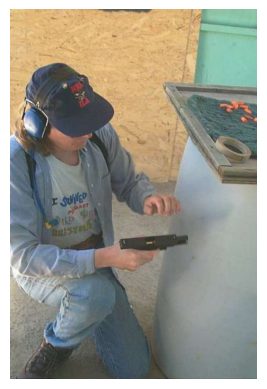

In [8]:
image_name = train_df.iloc[0]["name"]

image_path = DATA_DIR / "data" / "train" / image_name

print("Image name:", image_name)
print("Image exists:", image_path.exists())

if image_path.exists():
    image = Image.open(image_path).convert("RGB")

    print("Image size:", image.size)
    print("Image mode:", image.mode)

    plt.imshow(image)
    plt.axis("off")
    plt.show()

In [9]:
unsafe_columns = [
    "alcohol",
    "drugs",
    "weapons",
    "gambling",
    "nudity",
    "sexy",
    "smoking",
    "violence",
]

print("Number of categories:", len(unsafe_columns))

Number of categories: 8


In [10]:
category_counts = train_df[unsafe_columns].sum().sort_values(
    ascending=False
)

print("Positive labels in the training dataset:")
print(category_counts)

Positive labels in the training dataset:
violence    481
sexy        461
weapons     417
nudity      361
smoking     357
gambling    217
alcohol     213
drugs       177
dtype: int64


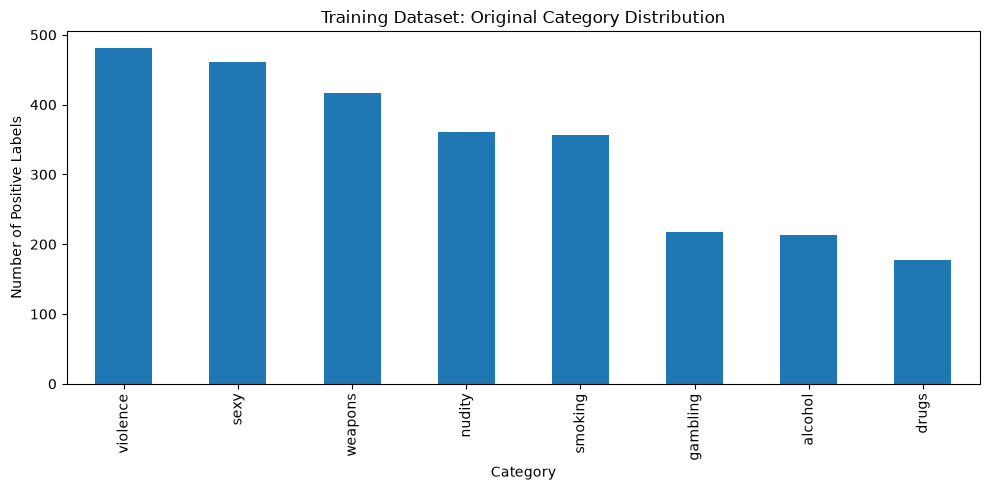

In [11]:
category_counts.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Training Dataset: Original Category Distribution")
plt.xlabel("Category")
plt.ylabel("Number of Positive Labels")
plt.tight_layout()
plt.show()

In [12]:
for split_name, df in [
    ("train", train_df),
    ("validation", val_df),
    ("test", test_df),
]:
    print(f"\nChecking {split_name} dataset")

    print("Missing category values:",
          df[unsafe_columns].isnull().sum().sum())

    print("Unique label values:",
          sorted(pd.unique(df[unsafe_columns].values.ravel())))


Checking train dataset
Missing category values: 0
Unique label values: [np.int64(0), np.int64(1)]

Checking validation dataset
Missing category values: 0
Unique label values: [np.int64(0), np.int64(1)]

Checking test dataset
Missing category values: 0
Unique label values: [np.int64(0), np.int64(1)]


In [13]:
for df in [train_df, val_df, test_df]:
    df["unsafe"] = (
        df[unsafe_columns].sum(axis=1) > 0
    ).astype(int)

    df["binary_label"] = df["unsafe"].map({
        0: "safe",
        1: "unsafe"
    })

In [14]:
for split_name, df in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df),
]:
    print(f"\n{split_name} dataset")
    print(df["binary_label"].value_counts())


Train dataset
binary_label
unsafe    1900
safe      1709
Name: count, dtype: int64

Validation dataset
binary_label
unsafe    402
safe      369
Name: count, dtype: int64

Test dataset
binary_label
unsafe    409
safe      364
Name: count, dtype: int64


In [15]:
DATA_DIR = Path(
    "/Users/kakulrajput/Documents/Image_Detection/data/raw/harmful-contents"
)

CSV_DIR = DATA_DIR / "csv"
IMAGE_DIR = DATA_DIR / "data"

print("Dataset exists:", DATA_DIR.exists())
print("CSV directory exists:", CSV_DIR.exists())
print("Image directory exists:", IMAGE_DIR.exists())

Dataset exists: True
CSV directory exists: True
Image directory exists: True


In [16]:
splits = {
    "train": train_df,
    "val": val_df,
    "test": test_df,
}

missing_images = []

for split_name, df in splits.items():
    for filename in df["name"]:
        image_path = IMAGE_DIR / split_name / filename

        if not image_path.is_file():
            missing_images.append({
                "split": split_name,
                "filename": filename,
                "expected_path": str(image_path),
            })

print("Total missing images:", len(missing_images))

if missing_images:
    print(missing_images[:10])
else:
    print("All CSV filenames have corresponding image files.")

Total missing images: 0
All CSV filenames have corresponding image files.


In [17]:
train_names = set(train_df["name"])
val_names = set(val_df["name"])
test_names = set(test_df["name"])

print("Train-validation overlap:", len(train_names & val_names))
print("Train-test overlap:", len(train_names & test_names))
print("Validation-test overlap:", len(val_names & test_names))

Train-validation overlap: 0
Train-test overlap: 0
Validation-test overlap: 0


In [22]:
invalid_images = []

for split_name, df in splits.items():
    for filename in tqdm(
        df["name"],
        desc=f"Checking {split_name} images"
    ):
        image_path = IMAGE_DIR / split_name / filename

        try:
            with Image.open(image_path) as image:
                image.verify()

        except Exception as error:
            invalid_images.append({
                "split": split_name,
                "filename": filename,
                "error": str(error),
            })

print("Unreadable images:", len(invalid_images))

if invalid_images:
    print(invalid_images[:10])
else:
    print("All referenced images passed the image integrity check.")

Checking train images:   0%|          | 0/3609 [00:00<?, ?it/s]

Checking val images:   0%|          | 0/771 [00:00<?, ?it/s]

Checking test images:   0%|          | 0/773 [00:00<?, ?it/s]

Unreadable images: 0
All referenced images passed the image integrity check.


In [24]:
DATA_DIR = Path(
    "/Users/kakulrajput/Documents/Image_Detection/data/raw/harmful-contents"
)

IMAGE_DIR = DATA_DIR / "data"
CSV_DIR = DATA_DIR / "csv"

PROJECT_DIR = Path(
    "/Users/kakulrajput/Documents/Image_Detection"
)

PROCESSED_DIR = PROJECT_DIR / "data" / "processed" / "image_dataset"

unsafe_columns = [
    "alcohol",
    "drugs",
    "weapons",
    "gambling",
    "nudity",
    "sexy",
    "smoking",
    "violence",
]

print("Raw dataset:", DATA_DIR)
print("Processed dataset:", PROCESSED_DIR)

Raw dataset: /Users/kakulrajput/Documents/Image_Detection/data/raw/harmful-contents
Processed dataset: /Users/kakulrajput/Documents/Image_Detection/data/processed/image_dataset


In [25]:
train_df = pd.read_csv(CSV_DIR / "train.csv")
val_df = pd.read_csv(CSV_DIR / "val.csv")
test_df = pd.read_csv(CSV_DIR / "test.csv")

splits = {
    "train": train_df,
    "val": val_df,
    "test": test_df,
}

for split_name, df in splits.items():
    print(split_name, df.shape)

train (3609, 17)
val (771, 17)
test (773, 17)


In [26]:
for split_name, df in splits.items():
    if df[unsafe_columns].isnull().any().any():
        raise ValueError(
            f"Missing category labels found in {split_name}"
        )

    valid_values = set(
        pd.unique(df[unsafe_columns].values.ravel())
    )

    if not valid_values.issubset({0, 1}):
        raise ValueError(
            f"Unexpected category values in {split_name}: {valid_values}"
        )

    df["unsafe"] = (
        df[unsafe_columns].sum(axis=1) > 0
    ).astype(int)

    df["binary_label"] = df["unsafe"].map({
        0: "safe",
        1: "unsafe",
    })

    print(f"\n{split_name.upper()}")
    print(df["binary_label"].value_counts())


TRAIN
binary_label
unsafe    1900
safe      1709
Name: count, dtype: int64

VAL
binary_label
unsafe    402
safe      369
Name: count, dtype: int64

TEST
binary_label
unsafe    409
safe      364
Name: count, dtype: int64


In [31]:
from pathlib import Path

PROCESSED_DIR = (
    PROJECT_DIR / "data" / "processed" / "image_dataset"
)

if PROCESSED_DIR.exists():
    print("Processed dataset already exists.")
    print("Reusing:", PROCESSED_DIR)
else:
    for split_name in ["train", "val", "test"]:
        for label in ["safe", "unsafe"]:
            (
                PROCESSED_DIR / split_name / label
            ).mkdir(parents=True, exist_ok=True)

    print("Processed dataset folders created successfully.")

Processed dataset already exists.
Reusing: /Users/kakulrajput/Documents/Image_Detection/data/processed/image_dataset


In [32]:
expected_counts = {
    "train": {"safe": 1709, "unsafe": 1900},
    "val": {"safe": 369, "unsafe": 402},
    "test": {"safe": 364, "unsafe": 409},
}

for split, labels in expected_counts.items():
    for label, expected in labels.items():
        folder = PROCESSED_DIR / split / label

        actual = sum(
            1 for file in folder.iterdir()
            if file.is_file()
        )

        print(f"{split}/{label}: {actual}")

        assert actual == expected, (
            f"Count mismatch in {split}/{label}: "
            f"expected {expected}, found {actual}"
        )

print("\nDataset verification successful!")

train/safe: 1709
train/unsafe: 1900
val/safe: 369
val/unsafe: 402
test/safe: 364
test/unsafe: 409

Dataset verification successful!


In [33]:
copied_count = 0
skipped_count = 0

for split_name, df in splits.items():
    source_split_dir = IMAGE_DIR / split_name

    for _, row in df.iterrows():
        filename = row["name"]
        label = row["binary_label"]

        source_path = source_split_dir / filename
        destination_path = PROCESSED_DIR / split_name / label / filename

        if not source_path.is_file():
            raise FileNotFoundError(
                f"Source image not found: {source_path}"
            )

        # Create the destination folder if necessary
        destination_path.parent.mkdir(
            parents=True,
            exist_ok=True
        )

        # Skip files that have already been copied
        if destination_path.exists():
            skipped_count += 1
            continue

        shutil.copy2(source_path, destination_path)
        copied_count += 1

print("New images copied:", copied_count)
print("Existing images skipped:", skipped_count)
print("Total processed:", copied_count + skipped_count)

New images copied: 0
Existing images skipped: 5153
Total processed: 5153


In [34]:
expected_counts = {
    "train": {"safe": 1709, "unsafe": 1900},
    "val": {"safe": 369, "unsafe": 402},
    "test": {"safe": 364, "unsafe": 409},
}

for split, labels in expected_counts.items():
    for label, expected in labels.items():
        folder = PROCESSED_DIR / split / label

        actual = sum(
            1 for file in folder.iterdir()
            if file.is_file()
        )

        print(f"{split}/{label}: {actual}")

        assert actual == expected, (
            f"Expected {expected} files, found {actual}"
        )

print("\nDataset verification successful!")

train/safe: 1709
train/unsafe: 1900
val/safe: 369
val/unsafe: 402
test/safe: 364
test/unsafe: 409

Dataset verification successful!


In [29]:
for split_name in ["train", "val", "test"]:
    print(f"\n{split_name.upper()}")

    for label in ["safe", "unsafe"]:
        folder = PROCESSED_DIR / split_name / label

        count = sum(
            1 for path in folder.iterdir()
            if path.is_file()
        )

        print(f"{label}: {count}")


TRAIN
safe: 1709
unsafe: 1900

VAL
safe: 369
unsafe: 402

TEST
safe: 364
unsafe: 409


In [30]:
from torchvision import transforms

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
])